# Data Quality Checks and Salary Analysis by Seniority Level

**Q1 — How much do data analysts earn at different seniority levels?**

This notebook follows four steps:
1. Load the data from the SQLite database.
2. Inspect the dataset and check its quality.
3. Prepare salary ranges using reported values and predictions where reported values are missing.
4. Compare salary ranges across seniority levels.

> **Note:** Reported and predicted salary values are combined for this analysis. The results should therefore be interpreted as estimates based on the collected vacancies, not as definitive market salary benchmarks.

## 1. Import libraries and connect to the database

In [30]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DB_PATH = Path.cwd().parent / "data" / "vacancies.db"

if not DB_PATH.exists():
    raise FileNotFoundError(f"Database file not found: {DB_PATH}")

print(f"Database: {DB_PATH.resolve()}")

Database: /Users/michaelpiasetskyi/Developer/Projects/habr-vacancies/data/vacancies.db


## 2. Load the data

In [31]:
with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql_query("SELECT * FROM vacancies_analytics", conn)
    vacancies_df = pd.read_sql_query("SELECT * FROM vacancies", conn)
    skills_long = pd.read_sql_query(
        """
        SELECT vs.vacancy_id, s.skill_id
        FROM vacancy_skills AS vs
        INNER JOIN skills AS s
            ON s.skill_id = vs.skill_id
        """,
        conn,
    )

print(f"Vacancies in analytics view: {len(df):,}")
print(f"Vacancies in source table: {len(vacancies_df):,}")
print(f"Vacancy-skill relationships: {len(skills_long):,}")

Vacancies in analytics view: 170
Vacancies in source table: 170
Vacancy-skill relationships: 1,360


## 3. Initial data inspection

Check the dataset dimensions, column data types, and missing values. This gives us an overview of the fields available for the analysis.

In [32]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")

display(
    pd.DataFrame({
        "Data type": df.dtypes.astype(str),
        "Non-null values": df.notna().sum(),
        "Missing values": df.isna().sum(),
        "Missing values, %": (df.isna().mean() * 100).round(1),
    }).sort_values("Missing values, %", ascending=False)
)

Rows: 170 | Columns: 19


,Data type,Non-null values,Missing values,"Missing values, %"
salary_to,float64,20,150,88.2
salary_from,float64,21,149,87.6
salary_mid,float64,22,148,87.1
salary_currency,str,22,148,87.1
grade,str,108,62,36.5
predicted_salary_from,float64,109,61,35.9
predicted_salary_to,float64,109,61,35.9
city,str,125,45,26.5
employment,str,138,32,18.8
published_at,str,170,0,0.0


## 4. Data quality checks

Check for fully duplicated rows, duplicate vacancy IDs, and missing values in key fields. These checks do not modify the source data.

In [33]:
quality_checks = pd.Series({
    "Fully duplicated rows": int(df.duplicated().sum()),
    "Duplicate vacancy IDs": int(df["vacancy_id"].duplicated().sum())
        if "vacancy_id" in df.columns else None,
    "Missing vacancy titles": int(df["title"].isna().sum())
        if "title" in df.columns else None,
    "Missing seniority levels": int(df["grade"].isna().sum())
        if "grade" in df.columns else None,
})

display(quality_checks.rename("Count").to_frame())

,Count
Fully duplicated rows,0
Duplicate vacancy IDs,0
Missing vacancy titles,0
Missing seniority levels,62


## 5. Prepare salary data

For each salary boundary, use the reported value when available and fill missing values with the corresponding prediction. Then calculate the midpoint of the salary range.

Vacancies with missing boundaries or an invalid range (the lower boundary is higher than the upper boundary) are excluded from the seniority-level comparison.

In [34]:
df_salary = df.copy()

# Reported values take priority; predictions fill in missing values
df_salary["final_from"] = df_salary["salary_from"].fillna(
    df_salary["predicted_salary_from"]
)
df_salary["final_to"] = df_salary["salary_to"].fillna(
    df_salary["predicted_salary_to"]
)

df_salary["salary_mid"] = df_salary[["final_from", "final_to"]].mean(axis=1)

salary_checks = pd.Series({
    "Missing lower boundary": int(df_salary["final_from"].isna().sum()),
    "Missing upper boundary": int(df_salary["final_to"].isna().sum()),
    "Lower boundary above upper boundary": int(
        (df_salary["final_from"] > df_salary["final_to"]).sum()
    ),
    "Complete salary ranges": int(
        df_salary[["final_from", "final_to"]].notna().all(axis=1).sum()
    ),
})

display(salary_checks.rename("Number of vacancies").to_frame())

,Number of vacancies
Missing lower boundary,40
Missing upper boundary,41
Lower boundary above upper boundary,0
Complete salary ranges,128


## 6. Reported and predicted salary values

Compare the availability of reported and predicted salary boundaries. These categories may overlap: a vacancy can have a reported lower boundary and a predicted upper boundary.

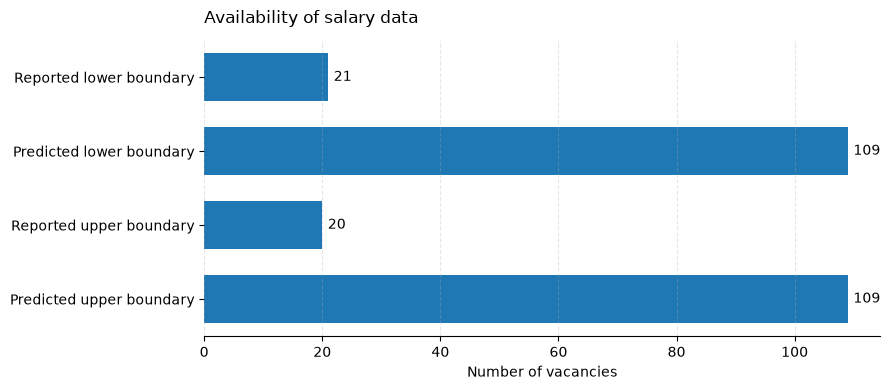

In [35]:
salary_source = pd.Series({
    "Reported lower boundary": int(df_salary["salary_from"].notna().sum()),
    "Predicted lower boundary": int(df_salary["predicted_salary_from"].notna().sum()),
    "Reported upper boundary": int(df_salary["salary_to"].notna().sum()),
    "Predicted upper boundary": int(df_salary["predicted_salary_to"].notna().sum()),
})

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    salary_source.index,
    salary_source.values,
    height=0.65,
)

ax.invert_yaxis()
ax.set_xlabel("Number of vacancies")
ax.set_title("Availability of salary data", loc="left", pad=12)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.bar_label(bars, padding=4, fmt="%.0f")

plt.tight_layout()
plt.show()

## 7. Salary ranges by seniority level

For each level, calculate:
- the number of vacancies included in the analysis;
- the median lower salary boundary;
- the median upper salary boundary;
- the median salary midpoint.

Medians are less sensitive to unusually high or low values than averages.

In [36]:
# Define the order of seniority levels
grade_order = ["Intern", "Junior", "Middle", "Senior", "Lead"]

salary_by_grade = df_salary.dropna(
    subset=["grade", "final_from", "final_to"]
).copy()

# Exclude invalid salary ranges
salary_by_grade = salary_by_grade[
    salary_by_grade["final_from"] <= salary_by_grade["final_to"]
]

grade_summary = (
    salary_by_grade.groupby("grade", observed=True).agg(
        vacancies=("vacancy_id", "count"),
        median_from=("final_from", "median"),
        median_to=("final_to", "median"),
        median_mid=("salary_mid", "median"),
    )
    .reindex(grade_order)
    .dropna(subset=["median_from", "median_to"])
    .reset_index()
)

display(
    grade_summary.style
    .format({
        "median_from": "{:,.0f} ₽",
        "median_to": "{:,.0f} ₽",
        "median_mid": "{:,.0f} ₽",
        "vacancies": "{:,.0f}",
    })
    .background_gradient(subset=["median_mid"], cmap="Blues")
    .set_caption("Median salary statistics by seniority level")
)

,grade,vacancies,median_from,median_to,median_mid
0,Intern,3,"65,000 ₽","87,000 ₽","76,000 ₽"
1,Junior,6,"111,000 ₽","168,500 ₽","139,750 ₽"
2,Middle,24,"169,500 ₽","250,500 ₽","209,750 ₽"
3,Senior,32,"247,500 ₽","281,000 ₽","258,750 ₽"
4,Lead,7,"331,000 ₽","445,000 ₽","395,000 ₽"


### Salary range visualization

The line represents the range between the median lower and upper salary boundaries. The marker shows the median salary midpoint.

This makes it easier to compare salary levels and range widths without overcrowding the chart.

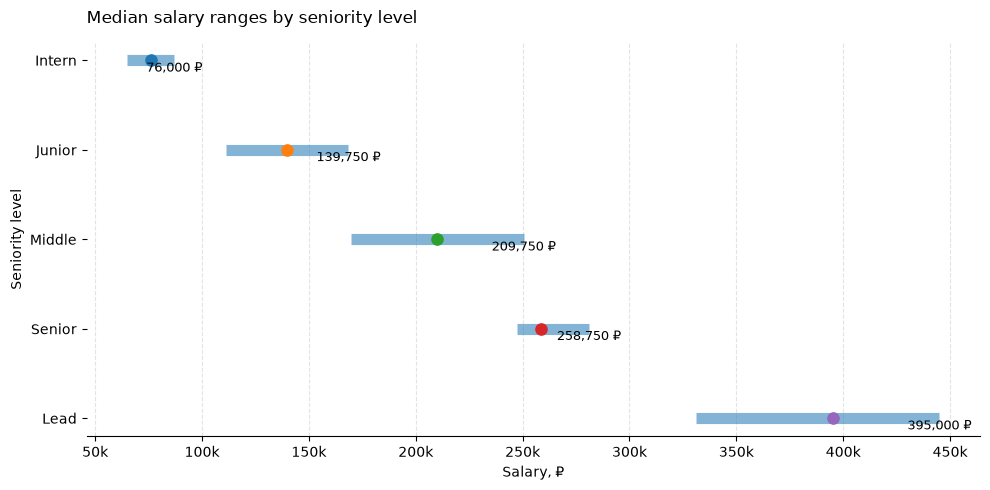

In [37]:
# Prepare data for plotting
plot_data = grade_summary.sort_values(
    "grade",
    key=lambda values: values.map(
        {grade: i for i, grade in enumerate(grade_order)}
    ),
).copy()

fig, ax = plt.subplots(figsize=(10, 5))

y_positions = np.arange(len(plot_data))

# Salary range: median lower and upper boundaries
for y, row in zip(y_positions, plot_data.itertuples()):
    ax.hlines(
        y=y,
        xmin=row.median_from,
        xmax=row.median_to,
        linewidth=8,
        alpha=0.55,
    )
    ax.scatter(row.median_mid, y, s=65, zorder=3)
    ax.text(
        row.median_to,
        y + 0.16,
        f"{row.median_mid:,.0f} ₽",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["grade"])
ax.invert_yaxis()
ax.set_xlabel("Salary, ₽")
ax.set_ylabel("Seniority level")
ax.set_title("Median salary ranges by seniority level", loc="left", pad=14)
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value / 1_000:.0f}k")
)

plt.tight_layout()
plt.show()

## 8. Q1 summary

When interpreting the results, keep the following points in mind:

- The comparison includes only vacancies with both salary boundaries available after preparation.
- The prepared salary fields may contain both reported and predicted values.
- The number of vacancies can differ across seniority levels, so sample size should be considered alongside the medians.

**Q1 conclusion:** Use the table and chart to compare median salary ranges across seniority levels and identify where the most noticeable increase occurs.